# Kamień 3 – ocena końcowa, analiza błędów i XAI

Model: E5 (EfficientNet-B0 + RandAugment + ważona CE) z kamienia 2.

- `SPLIT = "val"` – sprawdzenie, czy wszystko działa (zbiór walidacyjny)
- `SPLIT = "test"` – **ocena końcowa, uruchomić raz** na ostatecznym modelu

Aplikacja z Grad-CAM: `python app.py`

**Aktualne wyniki: zbiór walidacyjny.** Ocena na zbiorze testowym po decyzji o ewentualnym dłuższym treningu.

In [1]:
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import (balanced_accuracy_score, classification_report, confusion_matrix, f1_score,
                             recall_score, roc_auc_score, roc_curve)

from model import CLASSES, gradcam, load_image, load_model, overlay, to_tensor

SPLIT = "val"  # "val" = sprawdzenie, "test" = ocena końcowa (raz!)
CHECKPOINT = Path("out/models/E5_s0.pt")
DATA = Path("data")
MEL = CLASSES.index("mel")
SEED = 42
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")

model = load_model(CHECKPOINT)
paths = {p.stem: p for p in DATA.rglob("ISIC_*.jpg")}
splits = pd.read_csv(DATA / "splits.csv")
meta = pd.read_csv(DATA / "HAM10000_metadata.csv")
print(f"zbiór: {SPLIT}, model: {CHECKPOINT.name}, zdjęć: {len(paths)}")

zbiór: val, model: E5_s0.pt, zdjęć: 10015


## Predykcje

In [2]:
def predict(split):
    # prawdopodobieństwa 7 klas dla każdego zdjęcia; zapisujemy, żeby nie liczyć drugi raz
    f = Path(f"out/pred_{split}_{CHECKPOINT.stem}.csv")
    if f.exists():
        return pd.read_csv(f)
    df = splits[splits.split == split].reset_index(drop=True)
    probs = []
    with torch.no_grad():
        for i in range(0, len(df), 64):
            x = torch.cat([to_tensor(load_image(paths[j])) for j in df.image_id[i:i + 64]])
            probs.append(model(x).softmax(1).numpy())
    df[CLASSES] = np.concatenate(probs)
    df.to_csv(f, index=False)
    return df


val = predict("val")  # walidacja zawsze potrzebna – na niej dobieramy próg dla czerniaka
ev = val if SPLIT == "val" else predict("test")
y, p = ev.dx.map(CLASSES.index).values, ev[CLASSES].values
pred = p.argmax(1)
print(len(ev), "zdjęć w zbiorze", SPLIT)

1503 zdjęć w zbiorze val


## Metryki

In [3]:
def metrics(y, p, pred):
    return {
        "balanced accuracy": balanced_accuracy_score(y, pred),
        "macro-F1": f1_score(y, pred, average="macro"),
        "recall czerniaka": recall_score(y == MEL, pred == MEL),
        "AUC (makro)": roc_auc_score(y, p, multi_class="ovr"),
        "AUC czerniaka": roc_auc_score(y == MEL, p[:, MEL]),
    }


# 95% przedział ufności: bootstrap – 1000 razy losujemy zdjęcia ze zwracaniem i liczymy metrykę od nowa
rng = np.random.default_rng(SEED)
boot = {k: [] for k in ["balanced accuracy", "recall czerniaka"]}
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    boot["balanced accuracy"].append(balanced_accuracy_score(y[i], pred[i]))
    boot["recall czerniaka"].append(recall_score(y[i] == MEL, pred[i] == MEL))

y_val, p_val = val.dx.map(CLASSES.index).values, val[CLASSES].values
table = pd.DataFrame({"walidacja": metrics(y_val, p_val, p_val.argmax(1)), SPLIT: metrics(y, p, pred)}).round(3)
table["95% CI"] = [f"{np.percentile(boot[k], 2.5):.3f} – {np.percentile(boot[k], 97.5):.3f}" if k in boot else ""
                   for k in table.index]
table

,walidacja,val,95% CI
balanced accuracy,0.815,0.815,0.776 – 0.850
macro-F1,0.746,0.746,
recall czerniaka,0.705,0.705,0.632 – 0.771
AUC (makro),0.970,0.970,
AUC czerniaka,0.914,0.914,


In [4]:
report = pd.DataFrame(classification_report(y, pred, labels=range(7), target_names=CLASSES, output_dict=True,
                                            zero_division=0)).T.loc[CLASSES]
report.round(3)

,precision,recall,f1-score,support
nv,0.963,0.843,0.899,1006.0
mel,0.490,0.705,0.578,166.0
bkl,0.660,0.752,0.703,165.0
bcc,0.761,0.870,0.812,77.0
akiec,0.685,0.740,0.712,50.0
vasc,0.704,0.905,0.792,21.0
df,0.615,0.889,0.727,18.0


## Macierz pomyłek

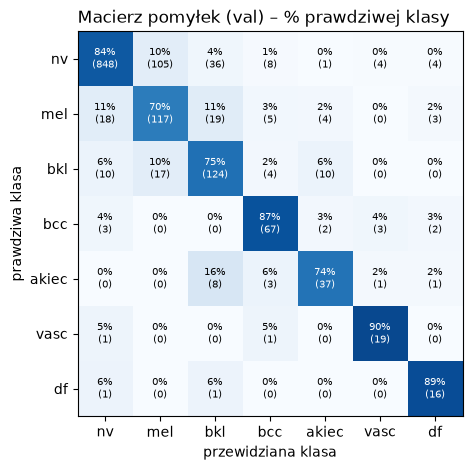

,prawdziwa,przewidziana,liczba
0,nv,mel,105
1,nv,bkl,36
2,mel,bkl,19
3,mel,nv,18
4,bkl,mel,17
5,bkl,nv,10


In [5]:
cm = confusion_matrix(y, pred, labels=range(7))
cm_pct = 100 * cm / cm.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{cm_pct[i, j]:.0f}%\n({cm[i, j]})", ha="center", va="center", fontsize=7.5,
                color="white" if cm_pct[i, j] > 55 else "black")
ax.set_xticks(range(7), CLASSES)
ax.set_yticks(range(7), CLASSES)
ax.set_xlabel("przewidziana klasa")
ax.set_ylabel("prawdziwa klasa")
ax.set_title(f"Macierz pomyłek ({SPLIT}) – % prawdziwej klasy", loc="left")
plt.show()

# najczęstsze pomyłki
off = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(7) for j in range(7) if i != j and cm[i, j] > 0]
pd.DataFrame(sorted(off, key=lambda t: -t[2])[:6], columns=["prawdziwa", "przewidziana", "liczba"])

## Próg decyzyjny dla czerniaka

Domyślnie model wybiera klasę o najwyższym prawdopodobieństwie. Można zamiast tego uznać zmianę za czerniaka,
gdy p(mel) ≥ t – niższy próg wykrywa więcej czerniaków kosztem fałszywych alarmów.
Próg dobieramy na **walidacji** (tak, by osiągnąć zadany recall), a sprawdzamy na zbiorze `SPLIT`.

In [6]:
def predict_with_threshold(p, t):
    # czerniak, jeśli p(mel) >= t; w przeciwnym razie najbardziej prawdopodobna z pozostałych klas
    other = p.copy()
    other[:, MEL] = -1
    return np.where(p[:, MEL] >= t, MEL, other.argmax(1))


def mel_row(name, pr):
    alarms = ((pr == MEL) & (y != MEL)).sum()
    return {"reguła": name, "recall mel": recall_score(y == MEL, pr == MEL),
            "precyzja mel": ((pr == MEL) & (y == MEL)).sum() / max((pr == MEL).sum(), 1),
            "fałszywe alarmy": alarms, "balanced acc.": balanced_accuracy_score(y, pr)}


rows = [mel_row("argmax (domyślnie)", pred)]
mel_val_probs = p_val[y_val == MEL, MEL]
for target in [0.80, 0.85, 0.90]:
    t = np.quantile(mel_val_probs, 1 - target)  # próg, przy którym na walidacji recall mel = target
    rows.append(mel_row(f"t = {t:.2f} (recall {target:.0%} na val)", predict_with_threshold(p, t)))
pd.DataFrame(rows).round(3)

,reguła,recall mel,precyzja mel,fałszywe alarmy,balanced acc.
0,argmax (domyślnie),0.705,0.490,122,0.815
1,t = 0.28 (recall 80% na val),0.801,0.358,238,0.795
2,t = 0.21 (recall 85% na val),0.849,0.329,288,0.779
3,t = 0.16 (recall 90% na val),0.898,0.300,347,0.765


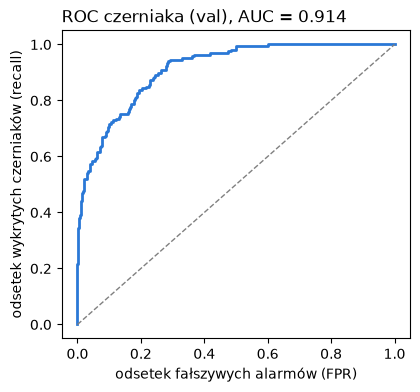

In [7]:
fpr, tpr, _ = roc_curve(y == MEL, p[:, MEL])
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(fpr, tpr, lw=2, color="#2a78d6")
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="gray")
ax.set_xlabel("odsetek fałszywych alarmów (FPR)")
ax.set_ylabel("odsetek wykrytych czerniaków (recall)")
ax.set_title(f"ROC czerniaka ({SPLIT}), AUC = {roc_auc_score(y == MEL, p[:, MEL]):.3f}", loc="left")
plt.show()

## Grad-CAM: czy model patrzy na zmianę? (H5)

Maski segmentacji zmian (Tschandl i in., Harvard Dataverse). Dla każdego zdjęcia liczymy, jaka część mapy Grad-CAM
leży **wewnątrz zmiany**. Punkt odniesienia: powierzchnia zmiany – tyle wyszłoby dla mapy rozłożonej równomiernie.

Mapa Grad-CAM z EfficientNet ma rozdzielczość tylko 7×7, więc przy małych zmianach „rozlewa się” poza maskę.
Dlatego liczymy też drugą miarę: czy **najsilniejszy punkt mapy** leży na zmianie.

In [8]:
MASKS = DATA / "HAM10000_segmentations_lesion_tschandl"
if not MASKS.exists():
    print("pobieranie masek (11 MB)...")
    urllib.request.urlretrieve("https://dataverse.harvard.edu/api/access/datafile/3838943", DATA / "masks.zip")
    z = zipfile.ZipFile(DATA / "masks.zip")
    z.extractall(DATA, members=[n for n in z.namelist() if not n.startswith("__MACOSX")])


def load_mask(image_id):
    # maska przeskalowana tak samo jak zdjęcie (do kwadratu 224x224)
    m = Image.open(MASKS / f"{image_id}_segmentation.png").convert("L").resize((224, 224), Image.NEAREST)
    return np.array(m) > 127


inside, area, peak = [], [], []
for k, image_id in enumerate(ev.image_id):
    cam, _, _ = gradcam(model, to_tensor(load_image(paths[image_id])), int(pred[k]))
    mask = load_mask(image_id)
    inside.append((cam * mask).sum() / cam.sum())
    area.append(mask.mean())
    peak.append(mask[np.unravel_index(cam.argmax(), cam.shape)])  # czy maksimum mapy jest na zmianie
    if k % 300 == 0:
        print(k, "/", len(ev))
ev["inside"], ev["area"], ev["peak"], ev["correct"] = inside, area, peak, pred == y

0 / 1503


300 / 1503


600 / 1503


900 / 1503


1200 / 1503


1500 / 1503


In [9]:
print(f"średnio {ev.inside.mean():.0%} mapy Grad-CAM leży na zmianie, a zmiana zajmuje średnio {ev.area.mean():.0%} zdjęcia")
print(f"najsilniejszy punkt mapy leży na zmianie w {ev.peak.mean():.0%} zdjęć")
g = ev.groupby("correct").agg(n=("inside", "size"), na_zmianie=("inside", "mean"), szczyt_na_zmianie=("peak", "mean"),
                             powierzchnia=("area", "mean"))
g.index = g.index.map({True: "poprawne", False: "błędne"})
g.round(3)

średnio 76% mapy Grad-CAM leży na zmianie, a zmiana zajmuje średnio 26% zdjęcia
najsilniejszy punkt mapy leży na zmianie w 99% zdjęć


,n,na_zmianie,szczyt_na_zmianie,powierzchnia
correct,,,,
błędne,275,0.734,0.993,0.268
poprawne,1228,0.769,0.995,0.263


In [10]:
ev.groupby("dx").agg(n=("inside", "size"), na_zmianie=("inside", "mean"), szczyt_na_zmianie=("peak", "mean"),
                     powierzchnia=("area", "mean"), trafność=("correct", "mean")).loc[CLASSES].round(3)

,n,na_zmianie,szczyt_na_zmianie,powierzchnia,trafność
dx,,,,,
nv,1006,0.763,0.996,0.239,0.843
mel,166,0.792,1.000,0.302,0.705
bkl,165,0.806,1.000,0.335,0.752
bcc,77,0.649,0.987,0.248,0.870
akiec,50,0.770,0.960,0.427,0.740
vasc,21,0.562,0.952,0.229,0.905
df,18,0.759,1.000,0.326,0.889


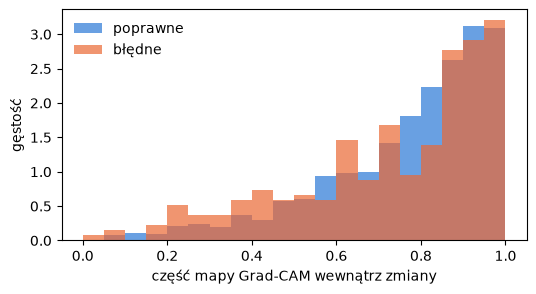

In [11]:
fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(0, 1, 21)
ax.hist(ev.inside[ev.correct], bins, alpha=0.7, density=True, label="poprawne", color="#2a78d6")
ax.hist(ev.inside[~ev.correct], bins, alpha=0.7, density=True, label="błędne", color="#eb6834")
ax.set_xlabel("część mapy Grad-CAM wewnątrz zmiany")
ax.set_ylabel("gęstość")
ax.legend(frameon=False)
plt.show()

zdjęć z maksimum mapy poza zmianą: 8 | w tym błędnych predykcji: 2


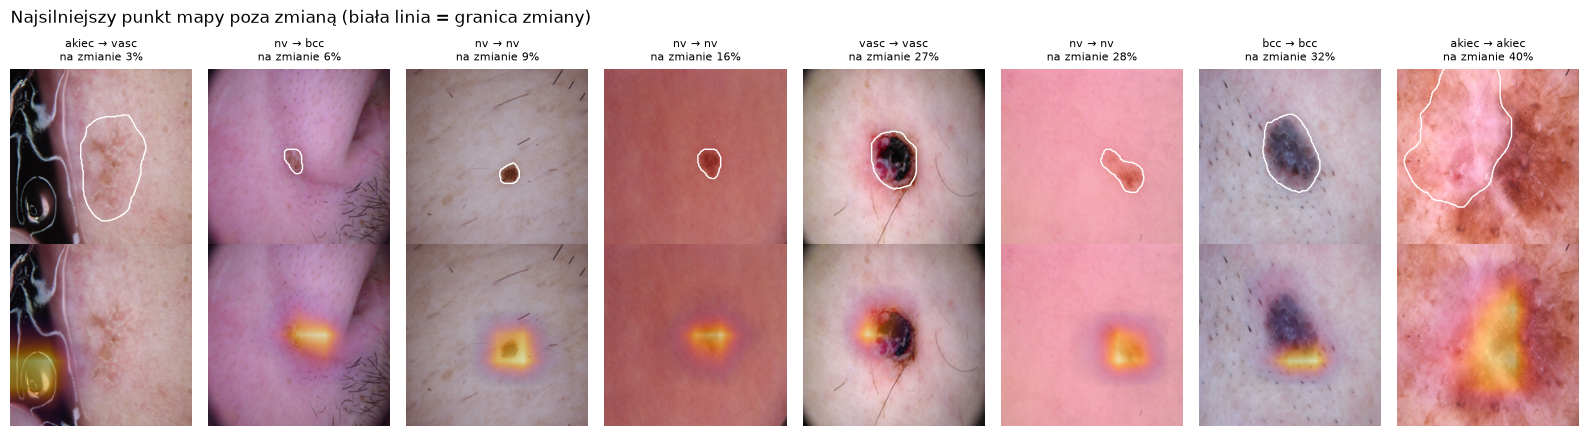

In [12]:
def gallery(df, title, n=8):
    df = df.head(n)
    if df.empty:
        print("brak przykładów")
        return
    fig, axes = plt.subplots(2, len(df), figsize=(2 * len(df), 4.4), squeeze=False)
    for k, (_, r) in enumerate(df.iterrows()):
        arr = load_image(paths[r.image_id])
        c = CLASSES.index(r.pred)
        cam, _, _ = gradcam(model, to_tensor(arr), c)
        axes[0, k].imshow(Image.fromarray(arr).resize((224, 224)))
        axes[0, k].contour(load_mask(r.image_id), levels=[0.5], colors="white", linewidths=1)
        axes[1, k].imshow(overlay(arr, cam))
        axes[0, k].set_title(f"{r.dx} → {r.pred}\nna zmianie {r.inside:.0%}", fontsize=8)
        for ax in axes[:, k]:
            ax.axis("off")
    fig.suptitle(title, x=0.01, ha="left")
    plt.tight_layout()
    plt.show()


ev["pred"] = [CLASSES[i] for i in pred]
print("zdjęć z maksimum mapy poza zmianą:", (~ev.peak).sum(), "| w tym błędnych predykcji:", (~ev.peak & ~ev.correct).sum())
gallery(ev[~ev.peak].sort_values("inside"), "Najsilniejszy punkt mapy poza zmianą (biała linia = granica zmiany)")

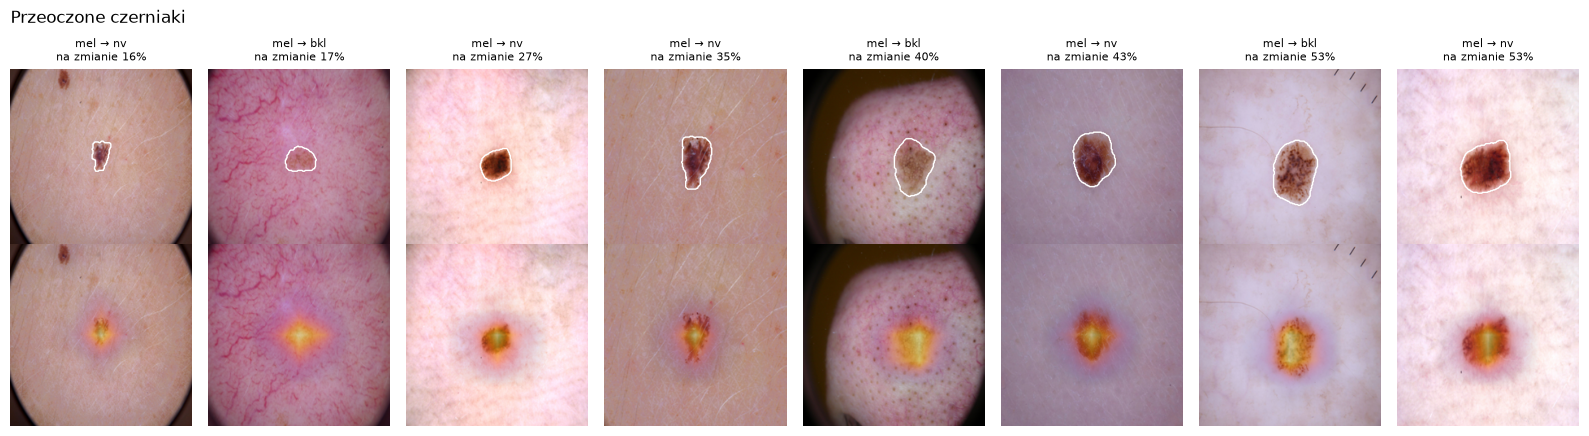

In [13]:
gallery(ev[(y == MEL) & (pred != MEL)].sort_values("inside"), "Przeoczone czerniaki")

## Wyniki wg źródła zdjęć

In [14]:
src = ev.merge(meta[["image_id", "dataset"]], on="image_id")
src.groupby("dataset").apply(lambda d: pd.Series({
    "n": len(d), "trafność": (d.pred == d.dx).mean(),
    "balanced acc.": balanced_accuracy_score(d.dx, d.pred) if d.dx.nunique() > 1 else np.nan,
}), include_groups=False).round(3)

,n,trafność,balanced acc.
dataset,,,
rosendahl,339.0,0.687,0.756
vidir_modern,495.0,0.715,0.818
vidir_molemax,604.0,0.969,0.858
vienna_dias,65.0,0.862,0.855


## Wnioski (walidacja – do potwierdzenia na teście)

- Wynik: balanced accuracy 0,815 (95% CI 0,78–0,85), recall czerniaka 0,705 (0,63–0,77), AUC czerniaka 0,914. Przedziały są szerokie, bo w zbiorze jest tylko 166 czerniaków.
- Najczęstszy błąd to nv → mel (105 zdjęć): ważona strata sprawia, że model woli fałszywy alarm niż przeoczenie. Przeoczone czerniaki są mylone głównie z bkl (19) i nv (18).
- Próg dla czerniaka: obniżając próg, można wykryć 80% czerniaków (238 fałszywych alarmów) albo 90% (347 alarmów) zamiast 71% (122 alarmy). Każde +10 pkt proc. recallu kosztuje ok. 100 fałszywych alarmów – wybór progu zależy od zastosowania (np. badania przesiewowe).
- H5 (patrzenie poza zmianę): raczej nie. Najsilniejszy punkt mapy Grad-CAM leży na zmianie w 99% zdjęć, a 76% mapy przypada na zmianę, która zajmuje średnio 26% kadru. Tylko 8 zdjęć ma maksimum mapy poza zmianą (2 z nich to błędy – np. ciemny obiekt przy krawędzi, fałda skóry), więc artefakty wpływają na decyzję rzadko.
- Ograniczenie Grad-CAM: mapa ma rozdzielczość 7×7, więc przy małych zmianach rozlewa się poza maskę – dlatego obok udziału mapy na zmianie liczymy położenie maksimum.
- Źródło zdjęć: trafność różni się między ośrodkami (69–97%), ale balanced accuracy dużo mniej (0,76–0,86) – różnica wynika głównie z innego składu klas (w vidir_molemax prawie wyłącznie znamiona).